In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/adult.csv')

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (48842, 15)


In [4]:
print("\nFirst 5 Rows:")
display(df.head())


First 5 Rows:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [5]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [6]:
print("\nData Types:")
print(df.dtypes)


Data Types:
age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object


In [7]:
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip()

In [8]:
print("\nWhitespace Removed Successfully!")


Whitespace Removed Successfully!


In [9]:
df.replace('?', np.nan, inplace=True)

In [10]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64


In [11]:
print("\nTotal Missing Values:", df.isnull().sum().sum())


Total Missing Values: 6465


In [12]:
df.dropna(inplace=True)

In [13]:
print("\nDataset Shape After Removing Missing Values:", df.shape)


Dataset Shape After Removing Missing Values: (45222, 15)


In [14]:
print("\nRemaining Missing Values:")
print(df.isnull().sum().sum())


Remaining Missing Values:
0


In [15]:
df.drop(columns=['fnlwgt', 'education'], inplace=True)

In [16]:
print("Dataset Shape After Dropping Columns:", df.shape)

Dataset Shape After Dropping Columns: (45222, 13)


In [17]:
print("\nRemaining Columns:")
print(df.columns.tolist())


Remaining Columns:
['age', 'workclass', 'educational-num', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


In [18]:
display(df.head())

,age,workclass,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
5,34,Private,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K


In [19]:
df['income'] = (df['income'] == '>50K').astype(int)

In [20]:
print("Income Value Counts:")
print(df['income'].value_counts())

Income Value Counts:
income
0    34014
1    11208
Name: count, dtype: int64


In [21]:
plt.figure(figsize=(7, 5))

<Figure size 700x500 with 0 Axes>

<Figure size 700x500 with 0 Axes>

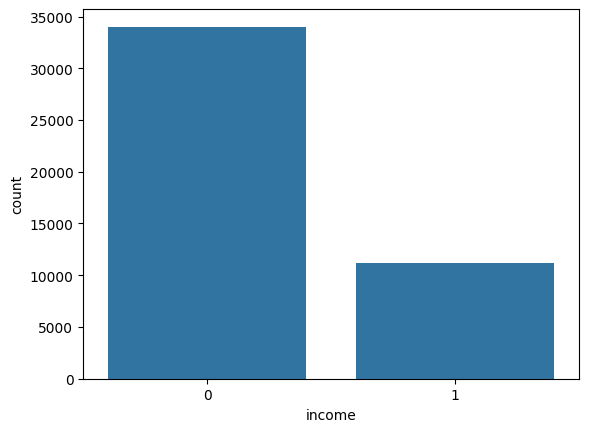

In [22]:
ax = sns.countplot(data=df, x='income')

Text(0, 0.5, 'Number of Individuals')

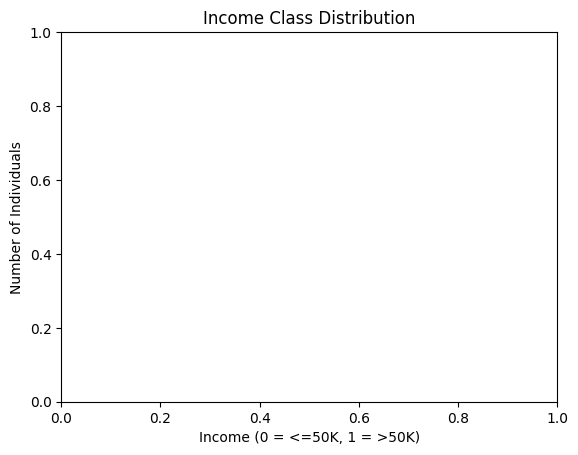

In [23]:
plt.title('Income Class Distribution')
plt.xlabel('Income (0 = <=50K, 1 = >50K)')
plt.ylabel('Number of Individuals')

In [24]:
for container in ax.containers:
    ax.bar_label(container)

plt.show()

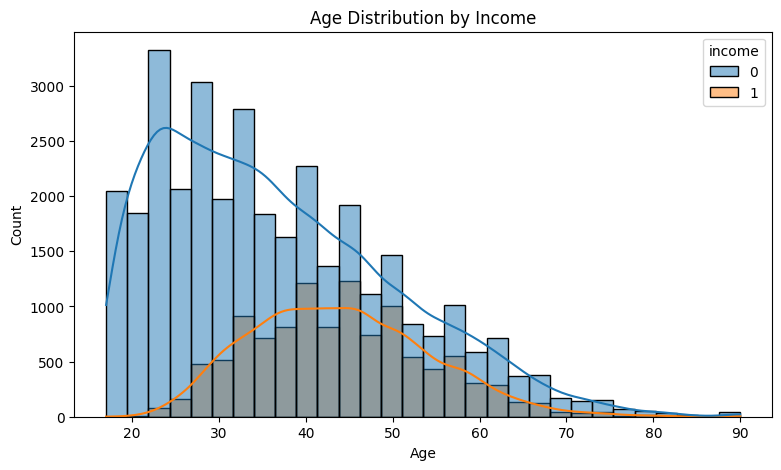

In [25]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='age',
    hue='income',
    bins=30,
    kde=True)
plt.title('Age Distribution by Income')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

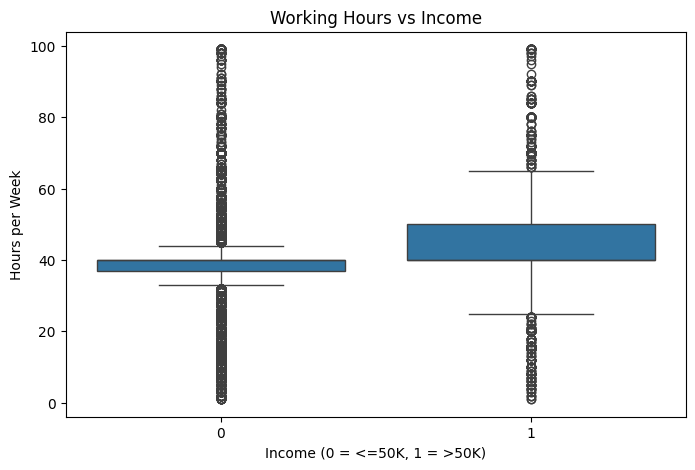

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='income',
    y='hours-per-week')
plt.title('Working Hours vs Income')
plt.xlabel('Income (0 = <=50K, 1 = >50K)')
plt.ylabel('Hours per Week')
plt.show()

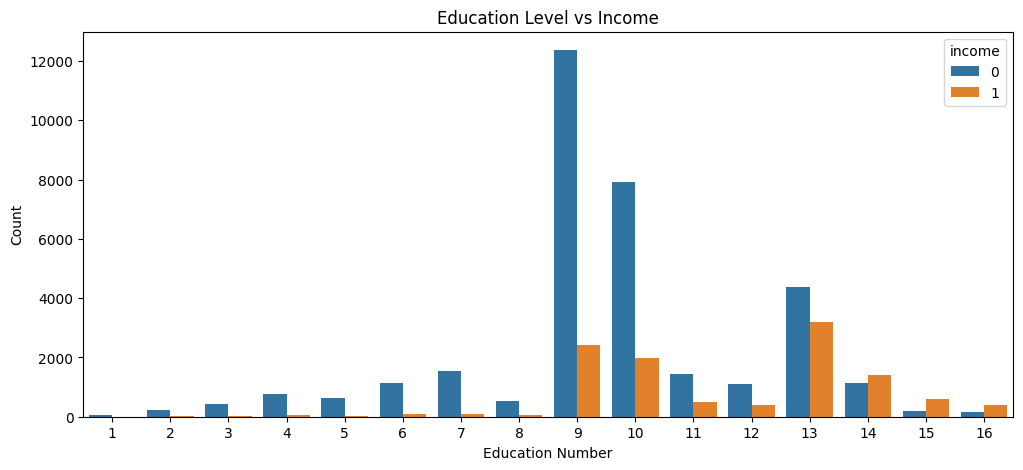

In [27]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x='educational-num',
    hue='income'
)

plt.title('Education Level vs Income')
plt.xlabel('Education Number')
plt.ylabel('Count')
plt.show()

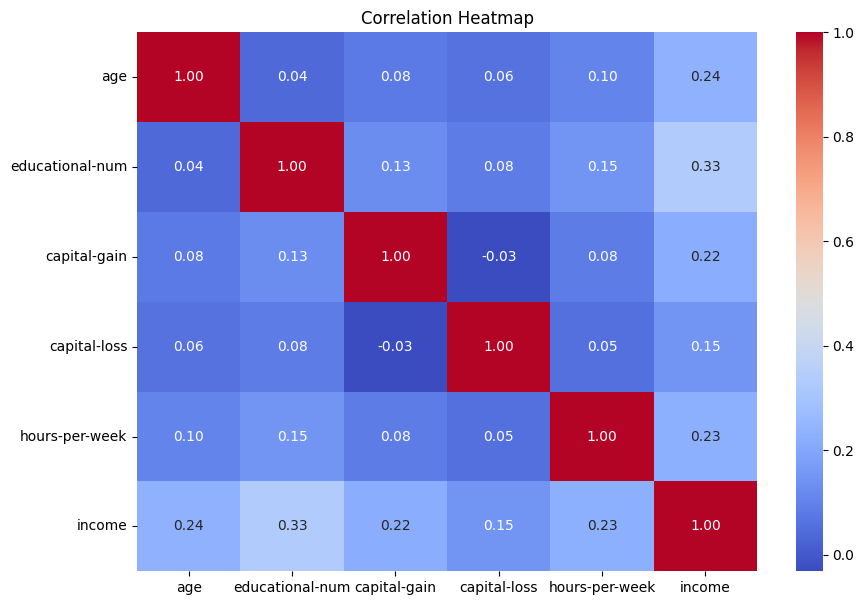

In [28]:
plt.figure(figsize=(10, 7))

numeric_data = df.select_dtypes(include=np.number)

correlation = numeric_data.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [29]:
X = df.drop('income', axis=1)
y = df['income']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (45222, 12)
Target Shape: (45222,)


In [30]:
X = pd.get_dummies(X, drop_first=True)

print("Shape After Encoding:", X.shape)
display(X.head())

Shape After Encoding: (45222, 80)


,age,educational-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,25,7,0,0,40,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,38,9,0,0,50,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,28,12,0,0,40,True,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,44,10,7688,0,40,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
5,34,6,0,0,30,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (36177, 80)
X_test Shape: (9045, 80)
y_train Shape: (36177,)
y_test Shape: (9045,)


In [32]:
from sklearn.preprocessing import StandardScaler

numeric_cols = [
    'age',
    'educational-num',
    'capital-gain',
    'capital-loss',
    'hours-per-week'
]

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

X_test.loc[:, numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

# Convert data into float32 for TensorFlow
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

y_train = y_train.astype('float32')
y_test = y_test.astype('float32')

print("Feature Scaling Completed!")

Feature Scaling Completed!


/tmp/ipykernel_4085/335401051.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.26789621 -1.47640119 -0.8721487  ...  0.26082472 -1.17427495
 -1.47640119]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_cols] = scaler.fit_transform(
/tmp/ipykernel_4085/335401051.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.43615486 -0.43615486 -0.43615486 ...  1.90323196  1.12343636
 -0.43615486]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_cols] = scaler.fit_transform(
/tmp/ipykernel_4085/335401051.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.14779435 -0.14779435 -0.14779435 ... -0.14779435 -0.14779435
 -0.14779435]' has dtype i

In [33]:
print("Training Income Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Income Distribution:")
print(y_test.value_counts(normalize=True))

Training Income Distribution:
income
0.0    0.752163
1.0    0.247837
Name: proportion, dtype: float64

Testing Income Distribution:
income
0.0    0.752128
1.0    0.247872
Name: proportion, dtype: float64


In [34]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [35]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),

    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),

    layers.Dense(1, activation='sigmoid')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,297 (28.50 KB)

 Trainable params: 7,297 (28.50 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])
print("Model Compiled Successfully!")

Model Compiled Successfully!


In [37]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1)

Epoch 1/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8424 - loss: 0.3380 - val_accuracy: 0.8495 - val_loss: 0.3224
Epoch 2/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8536 - loss: 0.3148 - val_accuracy: 0.8489 - val_loss: 0.3198
Epoch 3/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8545 - loss: 0.3121 - val_accuracy: 0.8494 - val_loss: 0.3197
Epoch 4/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8552 - loss: 0.3087 - val_accuracy: 0.8465 - val_loss: 0.3256
Epoch 5/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8575 - loss: 0.3065 - val_accuracy: 0.8488 - val_loss: 0.3195
Epoch 6/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8586 - loss: 0.3048 - val_accuracy: 0.8478 - val_loss: 0.3207
Epoch 7/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8608 - loss: 0.3025 - val_accuracy: 0.8507 - val_loss: 0.3197
Epoch 8/20
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8587 - loss: 0.3012 - val_accuracy: 0.

In [38]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

283/283 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8468 - loss: 0.3271
Test Loss: 0.3271160423755646
Test Accuracy: 0.8467661738395691
Test Accuracy (%): 84.67661738395691


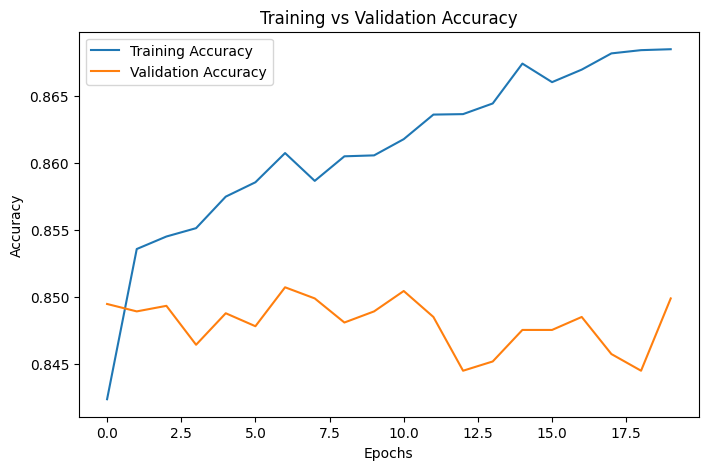

In [39]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

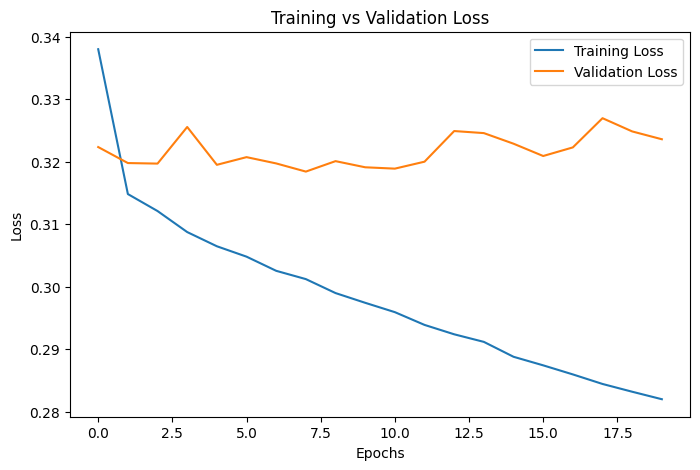

In [40]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [41]:
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()
print("Actual Values:", y_test[:10].values)
print("Predicted Values:", y_pred[:10])

283/283 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Actual Values: [0. 1. 0. 1. 0. 1. 0. 1. 0. 0.]
Predicted Values: [0 0 0 1 0 0 0 0 0 0]


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8467661691542289
Precision: 0.72790202342918
Recall: 0.6097234611953612
F1 Score: 0.6635922330097087

Classification Report:
              precision    recall  f1-score   support

         0.0       0.88      0.92      0.90      6803
         1.0       0.73      0.61      0.66      2242

    accuracy                           0.85      9045
   macro avg       0.80      0.77      0.78      9045
weighted avg       0.84      0.85      0.84      9045



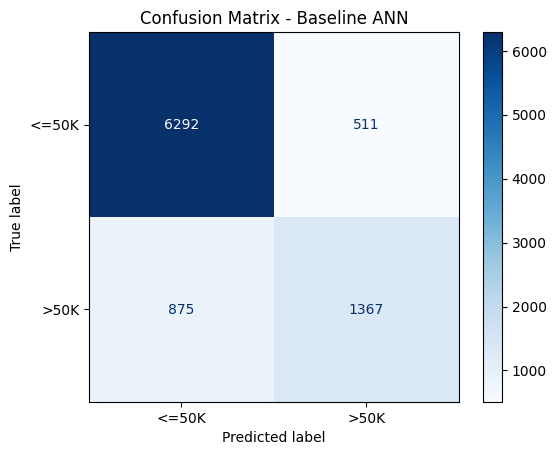

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['<=50K', '>50K']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - Baseline ANN')
plt.show()

In [44]:
def build_activation_model(activation):

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),

        layers.Dense(64, activation=activation),
        layers.Dense(32, activation=activation),

        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [45]:
activation_functions = ['relu', 'tanh', 'sigmoid', 'elu']

activation_results = {}

for activation in activation_functions:

    print(f"\nTraining Model with {activation.upper()} Activation")

    activation_model = build_activation_model(activation)

    history_activation = activation_model.fit(
        X_train,
        y_train,
        epochs=20,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    test_loss, test_accuracy = activation_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    activation_results[activation] = {
        'accuracy': test_accuracy,
        'loss': test_loss,
        'history': history_activation
    }

    print("Test Accuracy:", test_accuracy)
    print("Test Loss:", test_loss)


Training Model with RELU Activation
Test Accuracy: 0.8463239073753357
Test Loss: 0.32920852303504944

Training Model with TANH Activation
Test Accuracy: 0.8504145741462708
Test Loss: 0.31710681319236755

Training Model with SIGMOID Activation
Test Accuracy: 0.8499723672866821
Test Loss: 0.3166674077510834

Training Model with ELU Activation
Test Accuracy: 0.8444444537162781
Test Loss: 0.31849151849746704


In [46]:
activation_comparison = pd.DataFrame({
    'Activation Function': activation_results.keys(),
    'Test Accuracy': [
        activation_results[a]['accuracy']
        for a in activation_functions
    ],
    'Test Loss': [
        activation_results[a]['loss']
        for a in activation_functions
    ]
})

display(activation_comparison)

,Activation Function,Test Accuracy,Test Loss
0,relu,0.846324,0.329209
1,tanh,0.850415,0.317107
2,sigmoid,0.849972,0.316667
3,elu,0.844444,0.318492


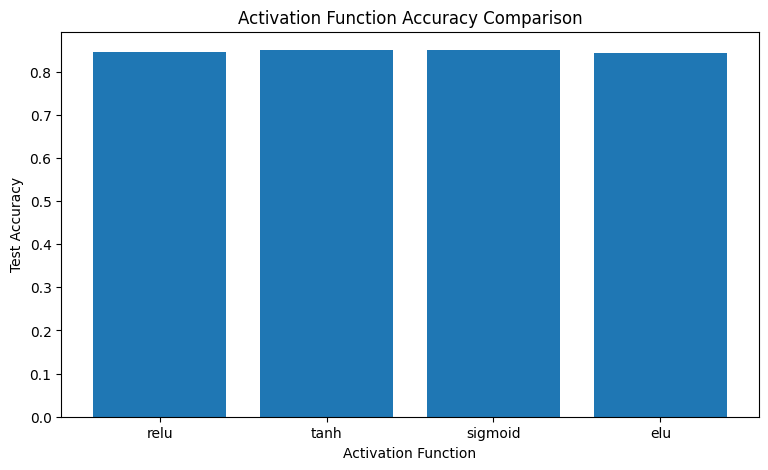

In [47]:
plt.figure(figsize=(9, 5))

plt.bar(
    activation_comparison['Activation Function'],
    activation_comparison['Test Accuracy']
)

plt.title('Activation Function Accuracy Comparison')
plt.xlabel('Activation Function')
plt.ylabel('Test Accuracy')
plt.show()

In [85]:
def build_initialization_model(initializer):

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),

        layers.Dense(
            64,
            activation='relu',
            kernel_initializer=initializer
        ),

        layers.Dense(
            32,
            activation='relu',
            kernel_initializer=initializer
        ),

        layers.Dense(
            1,
            activation='sigmoid',
            kernel_initializer='glorot_uniform'
        )
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [49]:
initializers = {
    'Glorot Uniform': 'glorot_uniform',
    'Glorot Normal': 'glorot_normal',
    'He Uniform': 'he_uniform',
    'He Normal': 'he_normal',
    'Zeros': 'zeros'
}

initialization_results = {}

for name, initializer in initializers.items():

    print(f"\nTraining with {name}")

    init_model = build_initialization_model(initializer)

    history_init = init_model.fit(
        X_train,
        y_train,
        epochs=20,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    test_loss, test_accuracy = init_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    initialization_results[name] = {
        'accuracy': test_accuracy,
        'loss': test_loss,
        'history': history_init,
        'model': init_model
    }

    print("Test Accuracy:", test_accuracy)
    print("Test Loss:", test_loss)


Training with Glorot Uniform
Test Accuracy: 0.8497512340545654
Test Loss: 0.3286081850528717

Training with Glorot Normal
Test Accuracy: 0.8473189473152161
Test Loss: 0.32846322655677795

Training with He Uniform
Test Accuracy: 0.8489773273468018
Test Loss: 0.32785263657569885

Training with He Normal
Test Accuracy: 0.8503040075302124
Test Loss: 0.3292607069015503

Training with Zeros
Test Accuracy: 0.7521282434463501
Test Loss: 0.5599849224090576


In [50]:
initialization_comparison = pd.DataFrame({
    'Initializer': initialization_results.keys(),

    'Test Accuracy': [
        initialization_results[name]['accuracy']
        for name in initializers
    ],

    'Test Loss': [
        initialization_results[name]['loss']
        for name in initializers
    ]
})

display(initialization_comparison)

,Initializer,Test Accuracy,Test Loss
0,Glorot Uniform,0.849751,0.328608
1,Glorot Normal,0.847319,0.328463
2,He Uniform,0.848977,0.327853
3,He Normal,0.850304,0.329261
4,Zeros,0.752128,0.559985


In [51]:
initialization_comparison = pd.DataFrame({
    'Initializer': initialization_results.keys(),

    'Test Accuracy': [
        initialization_results[name]['accuracy']
        for name in initializers
    ],

    'Test Loss': [
        initialization_results[name]['loss']
        for name in initializers
    ]
})

display(initialization_comparison)

,Initializer,Test Accuracy,Test Loss
0,Glorot Uniform,0.849751,0.328608
1,Glorot Normal,0.847319,0.328463
2,He Uniform,0.848977,0.327853
3,He Normal,0.850304,0.329261
4,Zeros,0.752128,0.559985


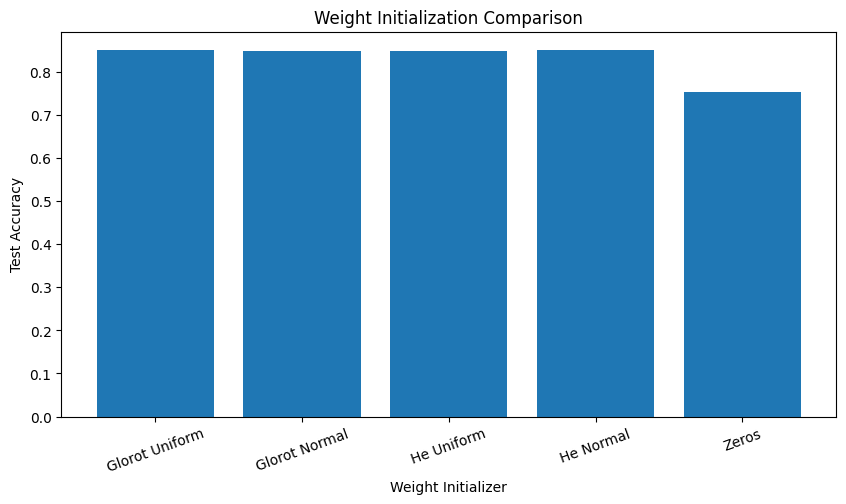

In [52]:
plt.figure(figsize=(10, 5))

plt.bar(
    initialization_comparison['Initializer'],
    initialization_comparison['Test Accuracy']
)

plt.title('Weight Initialization Comparison')
plt.xlabel('Weight Initializer')
plt.ylabel('Test Accuracy')
plt.xticks(rotation=20)
plt.show()

In [53]:
def focal_loss(gamma=2.0, alpha=0.25):

    def loss(y_true, y_pred):

        y_true = tf.cast(y_true, tf.float32)

        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(
            y_pred,
            epsilon,
            1.0 - epsilon
        )

        bce = keras.backend.binary_crossentropy(y_true, y_pred)

        p_t = y_true * y_pred + (1 - y_true) * (1 - y_pred)

        alpha_factor = y_true * alpha + (1 - y_true) * (1 - alpha)

        modulating_factor = tf.pow(1.0 - p_t, gamma)

        return alpha_factor * modulating_factor * bce

    return loss

In [54]:
def build_loss_model(loss_function):

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),

        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),

        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss=loss_function,
        metrics=['accuracy']
    )

    return model

In [55]:
loss_functions = {
    'Binary Crossentropy': 'binary_crossentropy',
    'Mean Squared Error': 'mean_squared_error',
    'Weighted BCE': keras.losses.BinaryCrossentropy(),
    'Focal Loss': focal_loss()
}

In [56]:
def weighted_bce(y_true, y_pred):

    weights = tf.where(
        tf.equal(y_true, 1),
        3.0,
        1.0
    )

    bce = keras.backend.binary_crossentropy(y_true, y_pred)

    return tf.reduce_mean(weights * bce)


loss_functions = {
    'Binary Crossentropy': 'binary_crossentropy',
    'Mean Squared Error': 'mean_squared_error',
    'Weighted BCE': weighted_bce,
    'Focal Loss': focal_loss()
}

In [57]:
loss_results = {}

for name, loss_function in loss_functions.items():

    print(f"\nTraining with {name}")

    loss_model = build_loss_model(loss_function)

    history_loss = loss_model.fit(
        X_train,
        y_train,
        epochs=20,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    test_loss, test_accuracy = loss_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    loss_results[name] = {
        'accuracy': test_accuracy,
        'loss': test_loss,
        'history': history_loss,
        'model': loss_model
    }

    print("Test Accuracy:", test_accuracy)
    print("Test Loss:", test_loss)


Training with Binary Crossentropy
Test Accuracy: 0.8530679941177368
Test Loss: 0.3236481845378876

Training with Mean Squared Error
Test Accuracy: 0.8501935005187988
Test Loss: 0.10332991182804108

Training with Weighted BCE
Test Accuracy: 0.7960199117660522
Test Loss: 0.5792140364646912

Training with Focal Loss
Test Accuracy: 0.8289662599563599
Test Loss: 0.03404608368873596


In [58]:
loss_comparison = pd.DataFrame({
    'Loss Function': loss_results.keys(),

    'Test Accuracy': [
        loss_results[name]['accuracy']
        for name in loss_functions
    ],

    'Test Loss': [
        loss_results[name]['loss']
        for name in loss_functions
    ]
})

display(loss_comparison)

,Loss Function,Test Accuracy,Test Loss
0,Binary Crossentropy,0.853068,0.323648
1,Mean Squared Error,0.850194,0.103330
2,Weighted BCE,0.796020,0.579214
3,Focal Loss,0.828966,0.034046


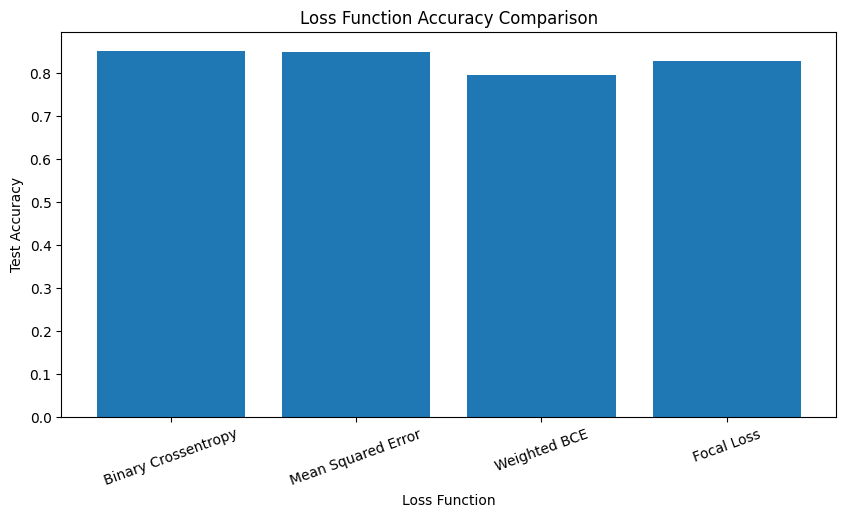

In [59]:
plt.figure(figsize=(10, 5))

plt.bar(
    loss_comparison['Loss Function'],
    loss_comparison['Test Accuracy']
)

plt.title('Loss Function Accuracy Comparison')
plt.xlabel('Loss Function')
plt.ylabel('Test Accuracy')
plt.xticks(rotation=20)
plt.show()

In [60]:
def build_model_without_bn():

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),

        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),

        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [61]:
def build_model_with_bn():

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),

        layers.Dense(64, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),

        layers.Dense(32, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),

        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [62]:
# Train model without Batch Normalization

model_without_bn = build_model_without_bn()

history_without_bn = model_without_bn.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)



model_with_bn = build_model_with_bn()

history_with_bn = model_with_bn.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

print("Both Models Trained Successfully!")

Both Models Trained Successfully!


In [63]:
loss_without_bn, acc_without_bn = model_without_bn.evaluate(
    X_test, y_test, verbose=0
)

loss_with_bn, acc_with_bn = model_with_bn.evaluate(
    X_test, y_test, verbose=0
)

bn_comparison = pd.DataFrame({
    'Model': ['Without Batch Normalization', 'With Batch Normalization'],
    'Test Accuracy': [acc_without_bn, acc_with_bn],
    'Test Loss': [loss_without_bn, loss_with_bn]
})

display(bn_comparison)

,Model,Test Accuracy,Test Loss
0,Without Batch Normalization,0.848977,0.325153
1,With Batch Normalization,0.849088,0.323082


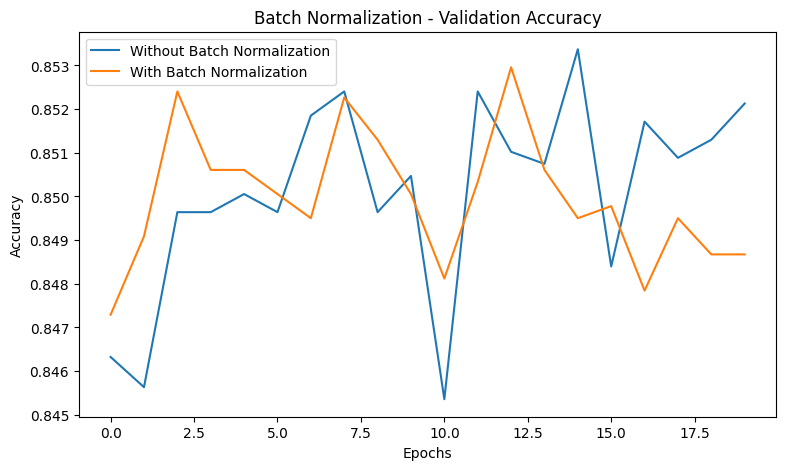

In [64]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_without_bn.history['val_accuracy'],
    label='Without Batch Normalization'
)

plt.plot(
    history_with_bn.history['val_accuracy'],
    label='With Batch Normalization'
)

plt.title('Batch Normalization - Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

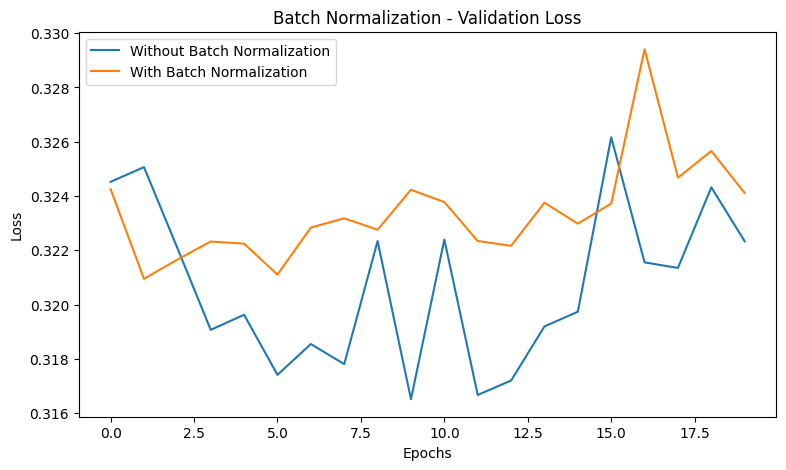

In [65]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_without_bn.history['val_loss'],
    label='Without Batch Normalization'
)

plt.plot(
    history_with_bn.history['val_loss'],
    label='With Batch Normalization'
)

plt.title('Batch Normalization - Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [66]:
def build_optimizer_model(optimizer):

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),

        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),

        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [67]:
optimizers = {
    'SGD': keras.optimizers.SGD(learning_rate=0.01),

    'SGD Momentum': keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    'RMSprop': keras.optimizers.RMSprop(
        learning_rate=0.001
    ),

    'Adam': keras.optimizers.Adam(
        learning_rate=0.001
    )
}

In [68]:
optimizer_results = {}

for name, optimizer in optimizers.items():

    print(f"\nTraining with {name}")

    optimizer_model = build_optimizer_model(optimizer)

    history_optimizer = optimizer_model.fit(
        X_train,
        y_train,
        epochs=20,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    test_loss, test_accuracy = optimizer_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    optimizer_results[name] = {
        'accuracy': test_accuracy,
        'loss': test_loss,
        'history': history_optimizer,
        'model': optimizer_model
    }

    print("Test Accuracy:", test_accuracy)
    print("Test Loss:", test_loss)


Training with SGD
Test Accuracy: 0.8514096140861511
Test Loss: 0.3200848698616028

Training with SGD Momentum
Test Accuracy: 0.8486456871032715
Test Loss: 0.31508755683898926

Training with RMSprop
Test Accuracy: 0.8529574275016785
Test Loss: 0.31925466656684875

Training with Adam
Test Accuracy: 0.8477612137794495
Test Loss: 0.3282198905944824


In [69]:
optimizer_comparison = pd.DataFrame({
    'Optimizer': optimizer_results.keys(),

    'Test Accuracy': [
        optimizer_results[name]['accuracy']
        for name in optimizers
    ],

    'Test Loss': [
        optimizer_results[name]['loss']
        for name in optimizers
    ]
})

display(optimizer_comparison)

,Optimizer,Test Accuracy,Test Loss
0,SGD,0.851410,0.320085
1,SGD Momentum,0.848646,0.315088
2,RMSprop,0.852957,0.319255
3,Adam,0.847761,0.328220


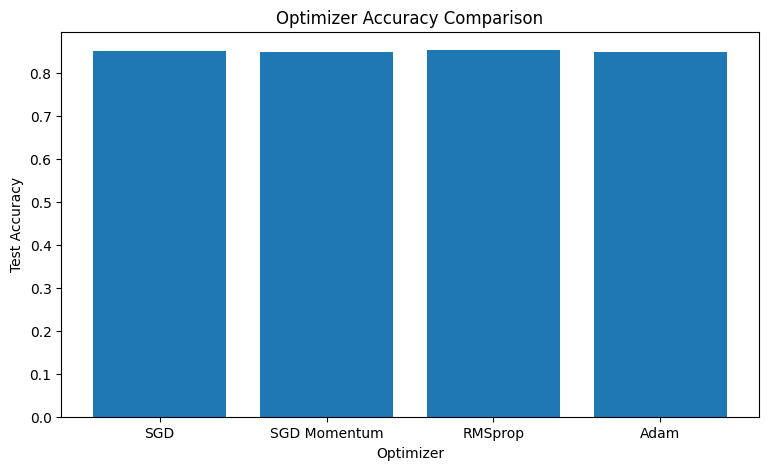

In [70]:
plt.figure(figsize=(9, 5))

plt.bar(
    optimizer_comparison['Optimizer'],
    optimizer_comparison['Test Accuracy']
)

plt.title('Optimizer Accuracy Comparison')
plt.xlabel('Optimizer')
plt.ylabel('Test Accuracy')
plt.show()

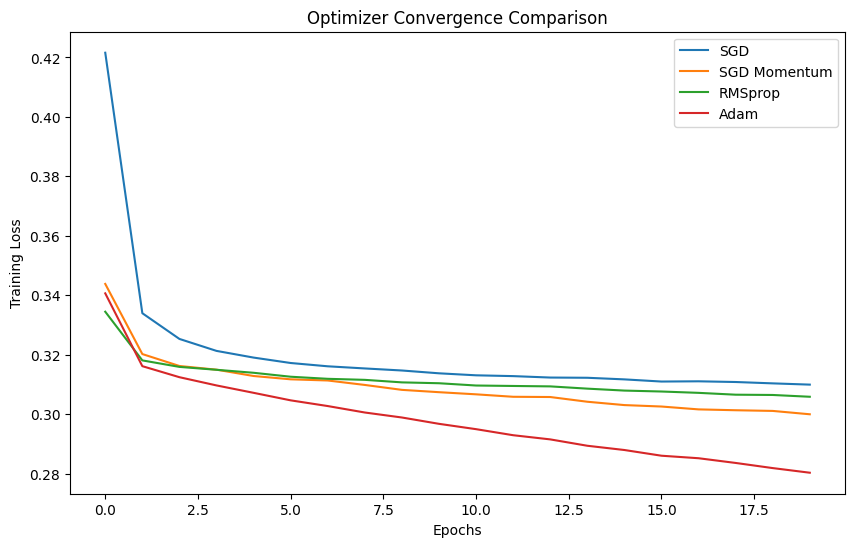

In [71]:
plt.figure(figsize=(10, 6))

for name in optimizers:

    plt.plot(
        optimizer_results[name]['history'].history['loss'],
        label=name
    )

plt.title('Optimizer Convergence Comparison')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.legend()
plt.show()

In [72]:
learning_rates = [0.1, 0.01, 0.001]
lr_results = {}

In [73]:
for lr in learning_rates:

    print(f"\nTraining with Learning Rate: {lr}")

    lr_model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),

        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),

        layers.Dense(1, activation='sigmoid')
    ])

    lr_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    history_lr = lr_model.fit(
        X_train,
        y_train,
        epochs=20,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    test_loss, test_accuracy = lr_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    lr_results[lr] = {
        'accuracy': test_accuracy,
        'loss': test_loss,
        'history': history_lr,
        'model': lr_model
    }

    print("Test Accuracy:", test_accuracy)
    print("Test Loss:", test_loss)


Training with Learning Rate: 0.1
Test Accuracy: 0.8216694593429565
Test Loss: 0.3494492471218109

Training with Learning Rate: 0.01
Test Accuracy: 0.8469873070716858
Test Loss: 0.3536379635334015

Training with Learning Rate: 0.001
Test Accuracy: 0.8448866605758667
Test Loss: 0.32783547043800354


In [74]:
lr_comparison = pd.DataFrame({
    'Learning Rate': lr_results.keys(),

    'Test Accuracy': [
        lr_results[lr]['accuracy']
        for lr in learning_rates
    ],

    'Test Loss': [
        lr_results[lr]['loss']
        for lr in learning_rates
    ]
})

display(lr_comparison)

,Learning Rate,Test Accuracy,Test Loss
0,0.100,0.821669,0.349449
1,0.010,0.846987,0.353638
2,0.001,0.844887,0.327835


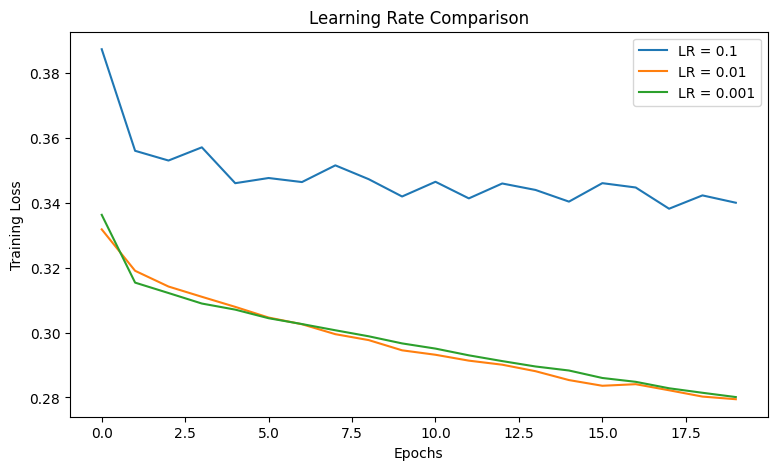

In [75]:
plt.figure(figsize=(9, 5))

for lr in learning_rates:

    plt.plot(
        lr_results[lr]['history'].history['loss'],
        label=f'LR = {lr}'
    )

plt.title('Learning Rate Comparison')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.legend()
plt.show()

In [76]:
final_model = keras.Sequential([

    layers.Input(shape=(X_train.shape[1],)),

    layers.Dense(64, kernel_initializer='he_normal', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Dense(32, kernel_initializer='he_normal', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    layers.Dense(1, activation='sigmoid')
])

final_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

final_model.summary()

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_69 (Dense)                │ (None, 64)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_70 (Dense)                │ (None, 32)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_71 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,585 (29.63 KB)

 Trainable params: 7,393 (28.88 KB)

 Non-trainable params: 192 (768.00 B)

In [77]:
final_history = final_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
905/905 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8354 - loss: 0.3571 - val_accuracy: 0.8449 - val_loss: 0.3289
Epoch 2/30
905/905 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8459 - loss: 0.3274 - val_accuracy: 0.8478 - val_loss: 0.3264
Epoch 3/30
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8489 - loss: 0.3231 - val_accuracy: 0.8483 - val_loss: 0.3244
Epoch 4/30
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8507 - loss: 0.3197 - val_accuracy: 0.8456 - val_loss: 0.3251
Epoch 5/30
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8519 - loss: 0.3181 - val_accuracy: 0.8458 - val_loss: 0.3257
Epoch 6/30
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8530 - loss: 0.3132 - val_accuracy: 0.8498 - val_loss: 0.3213
Epoch 7/30
905/905 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8536 - loss: 0.3124 - val_accuracy: 0.8491 - val_loss: 0.3232
Epoch 8/30
905/905 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8541 - loss: 0.3116 - val_accuracy: 0.

In [78]:
final_loss, final_accuracy = final_model.evaluate(
    X_test,
    y_test
)

print("Final Test Loss:", final_loss)
print("Final Test Accuracy:", final_accuracy)
print("Final Test Accuracy (%):", final_accuracy * 100)

283/283 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8462 - loss: 0.3286
Final Test Loss: 0.3285720646381378
Final Test Accuracy: 0.8462134003639221
Final Test Accuracy (%): 84.62134003639221


In [79]:
from sklearn.metrics import classification_report

final_probabilities = final_model.predict(X_test)

final_predictions = (
    final_probabilities >= 0.5
).astype(int).flatten()

print(classification_report(
    y_test,
    final_predictions,
    target_names=['<=50K', '>50K']
))

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

       <=50K       0.89      0.91      0.90      6803
        >50K       0.70      0.66      0.68      2242

    accuracy                           0.85      9045
   macro avg       0.80      0.78      0.79      9045
weighted avg       0.84      0.85      0.84      9045



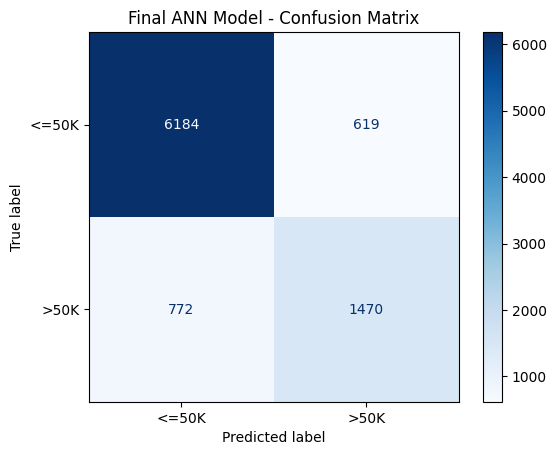

In [80]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

final_cm = confusion_matrix(y_test, final_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=['<=50K', '>50K']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Final ANN Model - Confusion Matrix')
plt.show()

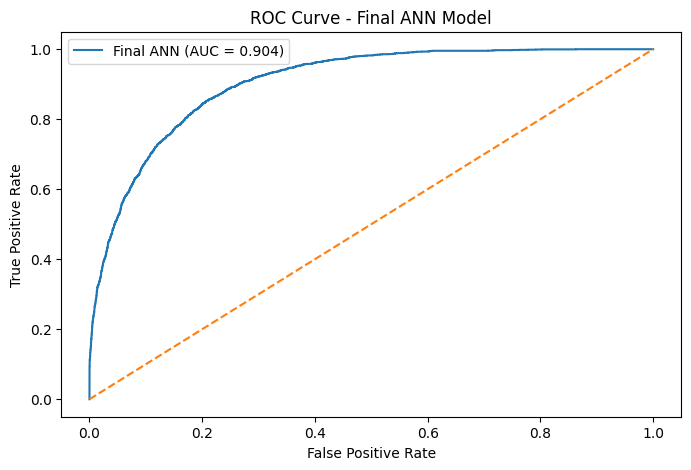

ROC-AUC Score: 0.9041884496830188


In [81]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_test,
    final_probabilities
)

auc_score = roc_auc_score(
    y_test,
    final_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label=f'Final ANN (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.title('ROC Curve - Final ANN Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

print("ROC-AUC Score:", auc_score)

In [82]:
# Final Experiment Comparison

all_results = []

# Activation Functions
for name, result in activation_results.items():
    all_results.append({
        'Experiment': 'Activation Function',
        'Technique': name,
        'Test Accuracy': result['accuracy'],
        'Test Loss': result['loss']
    })

# Weight Initialization
for name, result in initialization_results.items():
    all_results.append({
        'Experiment': 'Weight Initialization',
        'Technique': name,
        'Test Accuracy': result['accuracy'],
        'Test Loss': result['loss']
    })

# Loss Functions
for name, result in loss_results.items():
    all_results.append({
        'Experiment': 'Loss Function',
        'Technique': name,
        'Test Accuracy': result['accuracy'],
        'Test Loss': result['loss']
    })

# Optimizers
for name, result in optimizer_results.items():
    all_results.append({
        'Experiment': 'Optimizer',
        'Technique': name,
        'Test Accuracy': result['accuracy'],
        'Test Loss': result['loss']
    })

# Learning Rates
for name, result in lr_results.items():
    all_results.append({
        'Experiment': 'Learning Rate',
        'Technique': str(name),
        'Test Accuracy': result['accuracy'],
        'Test Loss': result['loss']
    })

# Batch Normalization
for name, accuracy, loss in [
    ('Without Batch Normalization', acc_without_bn, loss_without_bn),
    ('With Batch Normalization', acc_with_bn, loss_with_bn)
]:
    all_results.append({
        'Experiment': 'Batch Normalization',
        'Technique': name,
        'Test Accuracy': accuracy,
        'Test Loss': loss
    })

# Final Model
all_results.append({
    'Experiment': 'Final Model',
    'Technique': 'Combined ANN',
    'Test Accuracy': final_accuracy,
    'Test Loss': final_loss
})

final_results_table = pd.DataFrame(all_results)

display(final_results_table)

,Experiment,Technique,Test Accuracy,Test Loss
0,Activation Function,relu,0.846324,0.329209
1,Activation Function,tanh,0.850415,0.317107
2,Activation Function,sigmoid,0.849972,0.316667
3,Activation Function,elu,0.844444,0.318492
4,Weight Initialization,Glorot Uniform,0.849751,0.328608
5,Weight Initialization,Glorot Normal,0.847319,0.328463
6,Weight Initialization,He Uniform,0.848977,0.327853
7,Weight Initialization,He Normal,0.850304,0.329261
8,Weight Initialization,Zeros,0.752128,0.559985
9,Loss Function,Binary Crossentropy,0.853068,0.323648


In [83]:
final_results_table.to_csv(
    'final_experiment_results.csv',
    index=False
)

print("Final Results CSV Saved Successfully!")

Final Results CSV Saved Successfully!


In [84]:
from google.colab import files

files.download('final_experiment_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion

In this project, an Artificial Neural Network (ANN) was developed to predict whether an individual's annual income exceeds $50K using the Adult Income Dataset.

Different activation functions, weight initialization techniques, loss functions, batch normalization methods, optimizers, and learning rates were evaluated.

The performance of the models was compared using accuracy and loss. The final combined ANN model was evaluated using classification metrics, a confusion matrix, and an ROC curve.

This project demonstrates how different deep learning techniques influence model training and classification performance.
